In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
os.chdir("D:/gus6e/Documents")

In [87]:
data = pd.read_csv("recursos_humanos.csv")
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [88]:
data.drop(["number_project"], axis = 1, inplace = True)
data.head()

,satisfaction_level,last_evaluation,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,157,3,0,1,0,sales,low
1,0.80,0.86,262,6,0,1,0,sales,medium
2,0.11,0.88,272,4,0,1,0,sales,medium
3,0.72,0.87,223,5,0,1,0,sales,low
4,0.37,0.52,159,3,0,1,0,sales,low


In [89]:
A = data[data.left == 1] # Abandonó
P = data[data.left == 0] # Permaneció

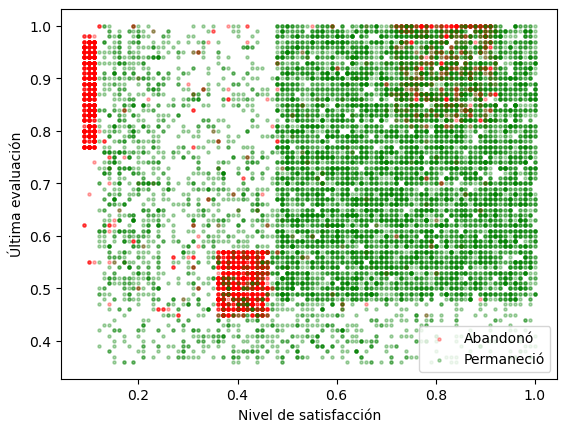

In [90]:
# Diagrama de dispersión
plt.scatter(A.satisfaction_level, A.last_evaluation, color = "red", s= 5, label = "Abandonó", alpha = 0.3)
plt.scatter(P.satisfaction_level, P.last_evaluation, color = "green", s = 5, label = "Permaneció", alpha = 0.3)
plt.xlabel("Nivel de satisfacción")
plt.ylabel("Última evaluación")
plt.legend()
plt.show()

In [91]:
# Número de observaciones de cada categoría
data.left.value_counts()

left
0    11428
1     3571
Name: count, dtype: int64

In [92]:
# Recodificación de las variables cualitativas con pd.get_dummies
data = pd.get_dummies(data, columns = ["sales", "salary"], dtype = int)
data.head()

,satisfaction_level,last_evaluation,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,157,3,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,262,6,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,272,4,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,223,5,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,159,3,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0


In [93]:
y = data.left.values
x_data = data.drop(["left"], axis = 1)

In [94]:
y

array([1, 1, 1, ..., 1, 1, 1], shape=(14999,))

In [95]:
x_data.head()

,satisfaction_level,last_evaluation,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,157,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,262,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,272,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,223,5,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,159,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0


In [96]:
# Normalización
x = (x_data - np.min(x_data)) / (np.max(x_data) - np.min(x_data))
x

,satisfaction_level,last_evaluation,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.001226,0.001710,0.506452,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.0,0.003226,0.000000
1,0.002581,0.002774,0.845161,0.019355,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.0,0.000000,0.003226
2,0.000355,0.002839,0.877419,0.012903,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.0,0.000000,0.003226
3,0.002323,0.002806,0.719355,0.016129,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.0,0.003226,0.000000
4,0.001194,0.001677,0.512903,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.0,0.003226,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.001290,0.001839,0.487097,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.003226,0.0,0.0,0.003226,0.000000
14995,0.001194,0.001548,0.516129,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.003226,0.0,0.0,0.003226,0.000000
14996,0.001194,0.001710,0.461290,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.003226,0.0,0.0,0.003226,0.000000
14997,0.000355,0.003097,0.903226,0.012903,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.003226,0.0,0.0,0.003226,0.000000


In [97]:
# Bases de entrenamiento y prueba
from sklearn.model_selection import  train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.30, random_state = 1)

In [98]:
# Modelo KNN (K vecinos más cercanos)
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(x_train,y_train)
prediction = knn.predict(x_test)
print("Score: ", knn.score(x_test,y_test))

Score:  0.8888888888888888


In [99]:
# Creación de la tabla de comparación para k = 1, 2, ..., 20
from sklearn.metrics import confusion_matrix
resultados = []
for k in range(1,21):
    knn = KNeighborsClassifier(n_neighbors = k)
    knn.fit(x_train,y_train)
    prediction = knn.predict(x_test)
    y_pred = prediction
    y_true = y_test
    cm = confusion_matrix(y_true,y_pred)
    correctos = cm[0,0] + cm[1,1]
    incorrectos = cm[0,1] + cm[1,0]
    precisionglobal = correctos / (correctos + incorrectos)
    precisionpermanece = cm[0,0] / (cm[0,0] + cm[1,0])
    precisionabandona = cm[1,1] / (cm[1,1] + cm[0,1])
    resultados.append([k,precisionglobal,precisionpermanece,precisionabandona])

tabla = pd.DataFrame(resultados, columns = ["K", "Precisión global", "Precisión permanece", "Precisión abandona"])
tabla

,K,Precisión global,Precisión permanece,Precisión abandona
0,1,0.910444,0.960563,0.777055
1,2,0.904889,0.929804,0.820312
2,3,0.888889,0.953640,0.727061
3,4,0.892667,0.931959,0.771946
4,5,0.886222,0.950372,0.724138
5,6,0.895333,0.938114,0.769096
6,7,0.890222,0.949815,0.735623
7,8,0.897333,0.939583,0.772807
8,9,0.896667,0.954140,0.747402
9,10,0.900222,0.946434,0.769754


In [100]:
# Modelo KNN con el valor de K seleccionado
knn = KNeighborsClassifier(n_neighbors = 1)
knn.fit(x_train,y_train)
prediction = knn.predict(x_test)
print("Score: ", knn.score(x_test,y_test))

Score:  0.9104444444444444


In [101]:
y_pred = prediction
y_true = y_test

In [102]:
# Creación de la matriz de confusión
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true,y_pred)
cm

array([[3142,  274],
       [ 129,  955]])

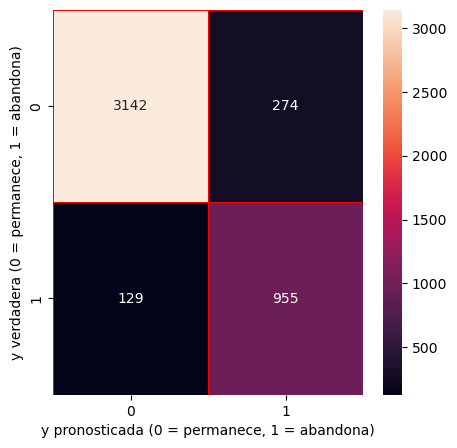

In [103]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize = (5,5))

sns.heatmap(cm,annot = True, linewidths = 0.5, linecolor = "red", fmt = ".0f", ax = ax)
plt.xlabel("y pronosticada (0 = permanece, 1 = abandona)")
plt.ylabel("y verdadera (0 = permanece, 1 = abandona)")
plt.show()

In [104]:
# Cálculo de la precisión global
correctos = cm[0,0] + cm[1,1]
incorrectos = cm[0,1] + cm[1,0]
precisionglobal = correctos/ (correctos + incorrectos)
precisionglobal

np.float64(0.9104444444444444)

In [105]:
precisionpermanece = cm[0,0] / (cm[0,0] + cm[1,0])
precisionpermanece

np.float64(0.9605625191073066)

In [106]:
precisionabandona = cm[1,1] / (cm[1,1] + cm[0,1])
precisionabandona

np.float64(0.7770545158665582)

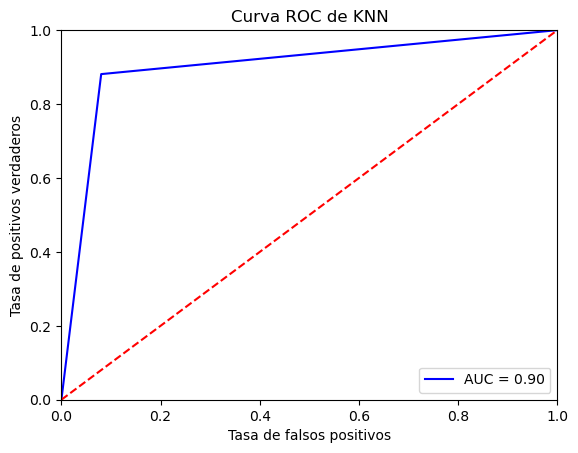

In [107]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

y_scores = knn.predict_proba(x_test)

# fpr = False positive rate, tpr = True positive rate
fpr, tpr, threshold = roc_curve(y_test, y_scores[:,1])
roc_auc = auc(fpr,tpr)

plt.title("Reciever Operating Characteristics")
plt.plot(fpr,tpr,"b", label = "AUC = %0.2f" % roc_auc)
plt.legend(loc = "lower right")
plt.plot([0,1],[0,1], "r--")
plt.xlim([0,1])
plt.ylim([0,1])
plt.ylabel("Tasa de positivos verdaderos")
plt.xlabel("Tasa de falsos positivos")
plt.title("Curva ROC de KNN")
plt.show()